In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay

In [2]:
X, y = make_moons(
    n_samples=500,
    noise=0.25,
    random_state=42
)

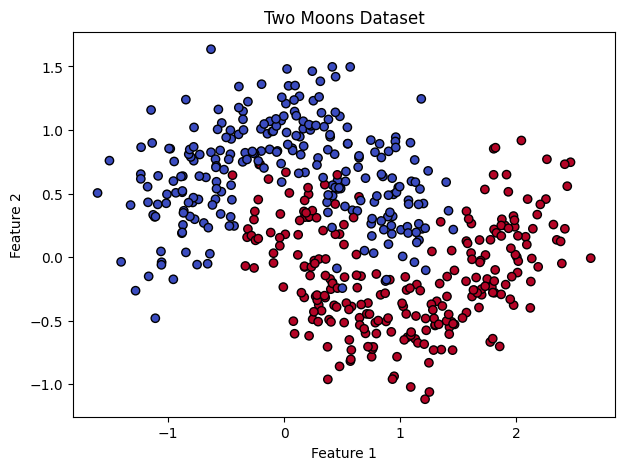

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
plt.title("Two Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
linear_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_svc = linear_model.named_steps["svc"]

print("Test accuracy:", accuracy_score(y_test, linear_pred))
print("Support vectors per class:", linear_svc.n_support_)
print("Total support vectors:", linear_svc.n_support_.sum())


Test accuracy: 0.83
Support vectors per class: [65 65]
Total support vectors: 130


In [9]:
rbf_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

rbf_model.fit(X_train, y_train)
rbf_pred = rbf_model.predict(X_test)

rbf_svc = rbf_model.named_steps["svc"]


print("Test accuracy:", accuracy_score(y_test, rbf_pred))
print("Support vectors per class:", rbf_svc.n_support_)
print("Total support vectors:", rbf_svc.n_support_.sum())




Test accuracy: 0.95
Support vectors per class: [53 54]
Total support vectors: 107


<Figure size 800x600 with 0 Axes>

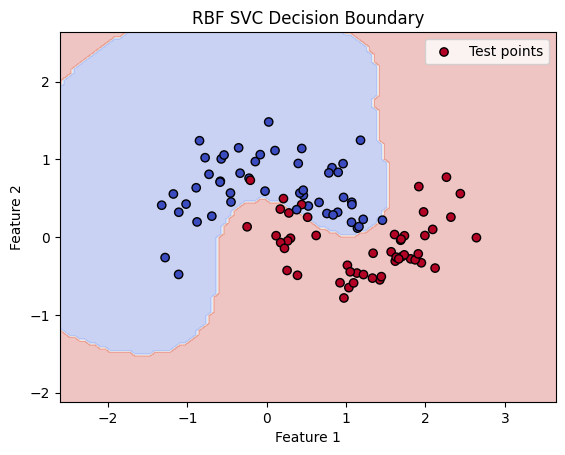

In [10]:
plt.figure(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    rbf_model,
    X,
    response_method="predict",
    plot_method="contourf",
    alpha=0.3,
    cmap="coolwarm"
)

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="coolwarm",
    edgecolors="k",
    label="Test points"
)

plt.title("RBF SVC Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

In [11]:
for C in [0.1, 1, 100]:
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=C)
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )
    test_acc = accuracy_score(
        y_test, model.predict(X_test)
    )

    svc = model.named_steps["svc"]

    print(f"\nC = {C}")
    print("Train accuracy:", train_acc)
    print("Test accuracy:", test_acc)
    print("Total support vectors:", svc.n_support_.sum())




C = 0.1
Train accuracy: 0.89
Test accuracy: 0.88
Total support vectors: 183

C = 1
Train accuracy: 0.94
Test accuracy: 0.95
Total support vectors: 107

C = 100
Train accuracy: 0.9625
Test accuracy: 0.95
Total support vectors: 51


In [12]:

for gamma in [0.1, 1, 30]:
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", gamma=gamma)
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )
    test_acc = accuracy_score(
        y_test, model.predict(X_test)
    )

    print(f"\ngamma = {gamma}")
    print("Train accuracy:", train_acc)
    print("Test accuracy:", test_acc)



gamma = 0.1
Train accuracy: 0.8625
Test accuracy: 0.86

gamma = 1
Train accuracy: 0.9575
Test accuracy: 0.95

gamma = 30
Train accuracy: 0.9725
Test accuracy: 0.93
